# NSGA-II & NSGA-II-FH — Multi-Objective Hardware-Aware NAS

**Objectives**: Maximize test accuracy · Minimize inference latency  
**Search space**: NAS-Bench-201 (15 625 unique CNN architectures)  
**Benchmarks**: HW-NAS-Bench (O(1) lookups, no training cost)  
**Algorithms**:
- **NSGA-II** — standard baseline (population Pareto front only)
- **NSGA-II-FH** — NSGA-II + Fixed-Hypergrid external archive (Patil 2020)

The external archive accumulates *every* non-dominated solution ever visited, yielding a significantly richer Pareto front without extra function evaluations.


## 0 · Configuration

In [1]:
import numpy as np

# ── Paths ─────────────────────────────────────────────────────────────────────
HW_NAS_ROOT   = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project\HW-NAS-Bench"
HW_NAS_PICKLE = f"{HW_NAS_ROOT}/HW-NAS-Bench-v1_0.pickle"
ACC_CSV       = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project\data\nasbench201_accuracies.csv"
OUTPUT_ROOT   = r"C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/working/nsga2_fh"

# ── Search config ─────────────────────────────────────────────────────────────
DATASET       = "cifar10"   # cifar10 | cifar100 | ImageNet16-120
HW_PLATFORM   = "raspi4"    # edgegpu | raspi4 | edgetpu | pixel3 | eyeriss | fpga
SEED          = 42

SEARCH_SPACE_SIZE = 15_625  # do NOT change

# ── NSGA-II hyper-parameters ──────────────────────────────────────────────────
POP_SIZE       = 100   # population size (must be even)
N_GENERATIONS  = 50    # number of generations
CROSSOVER_PROB = 0.9   # crossover probability
MUTATION_PROB  = 0.1   # mutation probability (per individual)
TOURNAMENT_K   = 2     # tournament selection size

# ── External archive (FH) hyper-parameters ───────────────────────────────────
# Reference values: set below the expected minimum of each objective
FH_REF_ACC  = 0.0    # reference accuracy (%)  — below any real accuracy
FH_REF_LAT  = 0.0    # reference latency (ms)  — below any real latency
FH_DELTA_ACC = 0.5   # grid spacing for accuracy (%)
FH_DELTA_LAT = 0.5   # grid spacing for latency (ms)
FH_MAX_CELLS = 2000  # max hypercubes tracked simultaneously
FH_MAX_SOLS  = 5     # max solutions stored per hypercube

np.random.seed(SEED)
print(f"Config : dataset={DATASET}, hw_platform={HW_PLATFORM}, seed={SEED}")
print(f"NSGA-II: pop={POP_SIZE}, generations={N_GENERATIONS}")
print(f"FH arch: delta_acc={FH_DELTA_ACC}%, delta_lat={FH_DELTA_LAT}ms, "
      f"max_cells={FH_MAX_CELLS}, max_sols/cell={FH_MAX_SOLS}")


Config : dataset=cifar10, hw_platform=raspi4, seed=42
NSGA-II: pop=100, generations=50
FH arch: delta_acc=0.5%, delta_lat=0.5ms, max_cells=2000, max_sols/cell=5


## 1 · Imports & setup

In [2]:
import sys, os, time
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from tqdm import tqdm

sys.path.insert(0, HW_NAS_ROOT)

plt.style.use("seaborn-v0_8-whitegrid")
os.makedirs(OUTPUT_ROOT, exist_ok=True)

print("Python", sys.version)
print("NumPy ", np.__version__)
print("Pandas", pd.__version__)


Python 3.13.5 | packaged by Anaconda, Inc. | (main, Jun 12 2025, 16:37:03) [MSC v.1929 64 bit (AMD64)]
NumPy  2.1.3
Pandas 2.2.3


## 2 · Load HW-NAS-Bench & accuracy table

In [3]:
from hw_nas_bench_api import HWNASBenchAPI as HWAPI

hw_api = HWAPI(HW_NAS_PICKLE, search_space="nasbench201")

LATENCY_KEY = f"{HW_PLATFORM}_latency"

sample = hw_api.query_by_index(0, DATASET)
print("Available HW keys:", list(sample.keys()))
assert LATENCY_KEY in sample, (
    f"Key '{LATENCY_KEY}' not found. Available: {list(sample.keys())}"
)
print(f"Latency key used : '{LATENCY_KEY}'")
print(f"Sample latency   : {sample[LATENCY_KEY]:.4f} ms")


Available HW keys: ['edgegpu_latency', 'edgegpu_energy', 'raspi4_latency', 'edgetpu_latency', 'pixel3_latency', 'eyeriss_latency', 'eyeriss_energy', 'eyeriss_arithmetic_intensity', 'fpga_latency', 'fpga_energy', 'average_hw_metric']
Latency key used : 'raspi4_latency'
Sample latency   : 10.4820 ms


## 3 · Accuracy lookup & evaluation helpers

In [4]:
acc_df = pd.read_csv(ACC_CSV).set_index("arch_index")

ACC_COL = f"acc_{DATASET}"
assert ACC_COL in acc_df.columns, (
    f"Column '{ACC_COL}' not found. Available: {list(acc_df.columns)}"
)

print(f"Accuracy table : {acc_df.shape[0]} architectures × {acc_df.shape[1]} datasets")
print(acc_df.head())


def get_accuracy(arch_index: int) -> float:
    """Test accuracy (%) for the configured dataset."""
    return float(acc_df.loc[arch_index, ACC_COL])


def get_latency(arch_index: int) -> float:
    """Inference latency (ms) for the configured platform."""
    return float(hw_api.query_by_index(arch_index, DATASET)[LATENCY_KEY])


def evaluate(arch_index: int):
    """Returns (accuracy, latency) for a given architecture index."""
    return get_accuracy(arch_index), get_latency(arch_index)


print(f"\nArch 0 — accuracy: {get_accuracy(0):.2f}%  latency: {get_latency(0):.4f} ms")


Accuracy table : 15625 architectures × 3 datasets
            acc_cifar10  acc_cifar100  acc_ImageNet16-120
arch_index                                               
0                 81.90         51.98           25.766667
1                 90.63         69.68           45.433333
2                 81.93         55.24           26.700000
3                 83.78         58.22           28.133333
4                 84.44         59.98           31.200000

Arch 0 — accuracy: 81.90%  latency: 10.4820 ms


## 4 · Exhaustive Pareto front (ground-truth reference)

In [5]:
print("Building exhaustive evaluation table (ground-truth Pareto front) …")
start = time.time()

all_results = []
for idx in tqdm(range(SEARCH_SPACE_SIZE), desc="Exhaustive scan"):
    acc, lat = evaluate(idx)
    all_results.append({"arch_index": idx, "accuracy": acc, "latency": lat})

df_all = pd.DataFrame(all_results)
print(f"Done in {time.time()-start:.2f}s")
print(f"Accuracy : {df_all['accuracy'].min():.2f}% – {df_all['accuracy'].max():.2f}%")
print(f"Latency  : {df_all['latency'].min():.4f} – {df_all['latency'].max():.4f} ms")


Building exhaustive evaluation table (ground-truth Pareto front) …


Exhaustive scan: 100%|██████████| 15625/15625 [00:00<00:00, 53832.05it/s]


Done in 0.32s
Accuracy : 10.00% – 91.49%
Latency  : 0.0113 – 98.8875 ms


## 5 · Shared utility functions

In [6]:
def is_pareto_front(acc_arr, lat_arr):
    """
    Returns a boolean mask of Pareto-optimal solutions.
    Objectives: maximize accuracy, minimize latency.
    """
    n = len(acc_arr)
    mask = np.ones(n, dtype=bool)
    for i in range(n):
        if not mask[i]:
            continue
        # Solution i is dominated if there exists j that is at least as good
        # on both objectives and strictly better on at least one.
        dominated = (
            (acc_arr >= acc_arr[i]) & (lat_arr <= lat_arr[i]) &
            ((acc_arr > acc_arr[i]) | (lat_arr < lat_arr[i]))
        )
        dominated[i] = False          # a solution cannot dominate itself
        if dominated.any():
            mask[i] = False
    return mask


def compute_pareto_df(df: pd.DataFrame) -> pd.DataFrame:
    mask = is_pareto_front(df["accuracy"].values, df["latency"].values)
    return df[mask].sort_values("accuracy", ascending=False).reset_index(drop=True)


def hypervolume_2d(pareto_df: pd.DataFrame, ref_point: tuple) -> float:
    """
    2-D hypervolume indicator for maximise-accuracy / minimise-latency.

    ref_point = (ref_lat, ref_acc) where
        ref_lat > every Pareto latency   (worst / rightmost latency)
        ref_acc < every Pareto accuracy  (worst accuracy)

    Algorithm (correct staircase sweep):
        Sort Pareto front by latency *descending* (right to left).
        Walk from ref_lat leftward; each point contributes a rectangle:
            width  = prev_lat - lat[i]
            height = acc[i]  - ref_acc
        This matches the standard 2-D hypervolume definition.
    """
    ref_lat, ref_acc = ref_point
    pts = pareto_df.sort_values("latency", ascending=False)[["accuracy", "latency"]].values
    hv = 0.0
    prev_lat = ref_lat
    for acc, lat in pts:
        if lat >= ref_lat:          # skip any point beyond the reference
            continue
        width  = prev_lat - lat
        height = acc - ref_acc
        if height > 0 and width > 0:
            hv += width * height
        prev_lat = lat
    return hv


# ── Ground-truth Pareto front ─────────────────────────────────────────────────
true_pareto = compute_pareto_df(df_all)
print(f"True Pareto front size : {len(true_pareto)} / {SEARCH_SPACE_SIZE}")
print(f"Best accuracy          : {true_pareto['accuracy'].max():.2f}%")
print(f"Best latency           : {true_pareto['latency'].min():.4f} ms")

# Reference point for all HV calculations
REF_LAT   = df_all["latency"].max() * 1.1
REF_ACC   = df_all["accuracy"].min() * 0.9
REF_POINT = (REF_LAT, REF_ACC)

hv_true = hypervolume_2d(true_pareto, REF_POINT)
print(f"True HV (ref={REF_POINT[0]:.2f}, {REF_POINT[1]:.2f}): {hv_true:.4f}")


True Pareto front size : 43 / 15625
Best accuracy          : 91.49%
Best latency           : 0.0113 ms
True HV (ref=108.78, 9.00): 8682.6448


## 6 · NSGA-II core components

Each individual is an **integer in [0, 15 624]** — its index in NAS-Bench-201.  
No architecture is trained: both objectives are **O(1) lookups** (CSV + pickle).

### Algorithm outline
1. **Initialise** a random population of `POP_SIZE` unique indices.
2. **Evaluate** each individual → (accuracy, latency).
3. **Non-dominated sort** → assign Pareto rank.
4. **Crowding distance** → secondary sorting criterion within a rank.
5. **Tournament selection** + **bit-level crossover** + **bit-flip mutation** → offspring.
6. **Combine** parent + offspring, sort, keep best `POP_SIZE` individuals.
7. Repeat for `N_GENERATIONS`.


In [7]:
# ─────────────────────────────────────────────────────────────────────────────
#  NSGA-II core components
# ─────────────────────────────────────────────────────────────────────────────

def fast_non_dominated_sort(objectives):
    """
    objectives : ndarray of shape (n, 2) — [accuracy, latency]
    Returns list of fronts (each front is a list of indices).
    Objective 0 (accuracy): maximised  |  Objective 1 (latency): minimised.
    """
    n   = len(objectives)
    acc = objectives[:, 0]
    lat = objectives[:, 1]

    dom_count = np.zeros(n, dtype=int)   # number of solutions that dominate i
    dom_set   = [[] for _ in range(n)]   # solutions dominated by i

    for i in range(n):
        for j in range(n):
            if i == j:
                continue
            # Does j dominate i?
            if (acc[j] >= acc[i] and lat[j] <= lat[i] and
                    (acc[j] > acc[i] or lat[j] < lat[i])):
                dom_count[i] += 1
            # Does i dominate j?
            elif (acc[i] >= acc[j] and lat[i] <= lat[j] and
                    (acc[i] > acc[j] or lat[i] < lat[j])):
                dom_set[i].append(j)

    fronts        = []
    current_front = [i for i in range(n) if dom_count[i] == 0]
    while current_front:
        fronts.append(current_front)
        next_front = []
        for i in current_front:
            for j in dom_set[i]:
                dom_count[j] -= 1
                if dom_count[j] == 0:
                    next_front.append(j)
        current_front = next_front
    return fronts


def crowding_distance(objectives, front):
    """
    Returns crowding distances for individuals in `front`.
    objectives : ndarray (n, 2)
    front      : list of indices into objectives
    """
    size      = len(front)
    distances = np.zeros(size)
    if size <= 2:
        distances[:] = np.inf
        return distances

    for m in range(objectives.shape[1]):
        vals   = objectives[front, m]
        order  = np.argsort(vals)
        f_min  = vals[order[0]]
        f_max  = vals[order[-1]]
        spread = f_max - f_min if f_max != f_min else 1e-8

        distances[order[0]]  = np.inf
        distances[order[-1]] = np.inf
        for k in range(1, size - 1):
            distances[order[k]] += (vals[order[k + 1]] - vals[order[k - 1]]) / spread

    return distances


def tournament_select(pop, ranks, cd, k=2):
    """k-way tournament — returns one winner index into pop."""
    candidates = np.random.choice(len(pop), k, replace=False)
    best = candidates[0]
    for c in candidates[1:]:
        if ranks[c] < ranks[best]:
            best = c
        elif ranks[c] == ranks[best] and cd[c] > cd[best]:
            best = c
    return best


def crossover(p1, p2):
    """
    Single-point crossover on the 14-bit binary representation of arch indices.
    (2^14 = 16 384 > 15 625, so 14 bits suffice to represent any valid index.)
    Result is clamped to [0, SEARCH_SPACE_SIZE - 1] via modulo.
    """
    if np.random.rand() > CROSSOVER_PROB:
        return p1, p2
    point = np.random.randint(1, 14)   # split point in [1, 13]
    mask  = (1 << point) - 1
    c1 = int(((p1 & ~mask) | (p2 & mask)) % SEARCH_SPACE_SIZE)
    c2 = int(((p2 & ~mask) | (p1 & mask)) % SEARCH_SPACE_SIZE)
    return c1, c2


def mutate(ind):
    """Flip a single random bit in the 14-bit representation."""
    if np.random.rand() > MUTATION_PROB:
        return ind
    bit = np.random.randint(0, 14)
    return int(ind ^ (1 << bit)) % SEARCH_SPACE_SIZE


print("NSGA-II core components defined.")


NSGA-II core components defined.


## 7 · Fixed-Hypergrid (FH) External Archive

Implementation of the archive management scheme from:
> Patil M B (2020). *Improved performance in multi-objective optimization using external archive.* Sādhanā 45:70.

### Key ideas
- The hypergrid has **no boundaries**: each cell is identified by a pair of integer indices computed from its position relative to fixed reference values and spacings.
- Only **occupied cells** are stored → memory proportional to number of distinct non-dominated regions, not to the full grid.
- When total cells (occupied + formerly occupied) exceed `FH_MAX_CELLS`, empty cells are **packed** (removed).
- The archive is updated **after every generation** but never participates in selection — it is purely a storage mechanism.


In [8]:
class FHArchive:
    """
    Fixed-Hypergrid external archive for 2-objective problems.

    Objectives
    ----------
    obj_0 : accuracy (%) — to be MAXIMISED
    obj_1 : latency  (ms) — to be MINIMISED

    Parameters
    ----------
    ref_acc   : float — reference (anchor) value for accuracy axis
    ref_lat   : float — reference (anchor) value for latency axis
    delta_acc : float — grid spacing along accuracy axis
    delta_lat : float — grid spacing along latency axis
    max_cells : int   — maximum number of hypercubes tracked (occupied + empty)
    max_sols  : int   — maximum solutions stored per hypercube (for pruning ties)
    """

    def __init__(self, ref_acc, ref_lat, delta_acc, delta_lat,
                 max_cells=2000, max_sols=5):
        self.ref_acc   = ref_acc
        self.ref_lat   = ref_lat
        self.delta_acc = delta_acc
        self.delta_lat = delta_lat
        self.max_cells = max_cells
        self.max_sols  = max_sols

        # cells: dict mapping (i_acc, i_lat) → list of (arch_index, acc, lat)
        self.cells: dict = {}
        # set of all arch_indices currently in the archive (for fast membership)
        self._members: set = set()

    # ── Cell index computation ─────────────────────────────────────────────
    def _cell_key(self, acc, lat):
        i_acc = int(np.floor((acc - self.ref_acc) / self.delta_acc))
        i_lat = int(np.floor((lat - self.ref_lat) / self.delta_lat))
        return (i_acc, i_lat)

    # ── Dominance check ───────────────────────────────────────────────────
    @staticmethod
    def _dominates(acc_a, lat_a, acc_b, lat_b):
        """Returns True if solution A dominates solution B."""
        return (acc_a >= acc_b and lat_a <= lat_b and
                (acc_a > acc_b or lat_a < lat_b))

    # ── Public interface ──────────────────────────────────────────────────
    def update(self, candidates):
        """
        Attempt to add each (arch_index, acc, lat) in `candidates` to the archive.

        Steps (Algorithm 2 from Patil 2020, adapted for the FH scheme):
        1. If the candidate is dominated by ANY archive member → reject.
        2. Remove all archive members dominated by the candidate.
        3. Locate the candidate's cell; add it (up to max_sols per cell).
        4. Pack empty cells if total cell count exceeds max_cells.
        """
        for arch_idx, acc, lat in candidates:
            if arch_idx in self._members:
                continue   # already stored

            # ── Step 1: check if candidate is dominated by any archive member ──
            dominated_by_archive = False
            for key, sols in self.cells.items():
                for (a_idx, a_acc, a_lat) in sols:
                    if self._dominates(a_acc, a_lat, acc, lat):
                        dominated_by_archive = True
                        break
                if dominated_by_archive:
                    break
            if dominated_by_archive:
                continue

            # ── Step 2: remove archive members dominated by the candidate ──────
            keys_to_check = list(self.cells.keys())
            for key in keys_to_check:
                remaining = [
                    s for s in self.cells[key]
                    if not self._dominates(acc, lat, s[1], s[2])
                ]
                removed = [s for s in self.cells[key]
                           if self._dominates(acc, lat, s[1], s[2])]
                for s in removed:
                    self._members.discard(s[0])
                self.cells[key] = remaining

            # ── Step 3: locate/create the candidate's cell and add it ──────────
            key = self._cell_key(acc, lat)
            if key not in self.cells:
                self.cells[key] = []

            cell_sols = self.cells[key]
            if len(cell_sols) < self.max_sols:
                cell_sols.append((arch_idx, acc, lat))
                self._members.add(arch_idx)
            else:
                # Cell is full: keep the solution with best accuracy-latency balance
                # (replace the one with the worst combined normalised distance)
                # Simple heuristic: replace the one with lowest accuracy among stored
                worst_idx = min(range(len(cell_sols)), key=lambda k: cell_sols[k][1])
                if acc > cell_sols[worst_idx][1]:
                    self._members.discard(cell_sols[worst_idx][0])
                    cell_sols[worst_idx] = (arch_idx, acc, lat)
                    self._members.add(arch_idx)

            # ── Step 4: pack empty cells if limit exceeded ────────────────────
            if len(self.cells) > self.max_cells:
                self._pack()

    def _pack(self):
        """Remove empty cells (cells whose solution list has become empty)."""
        self.cells = {k: v for k, v in self.cells.items() if v}

    def to_dataframe(self) -> pd.DataFrame:
        """Return all archive members as a DataFrame."""
        rows = []
        for sols in self.cells.values():
            for arch_idx, acc, lat in sols:
                rows.append({"arch_index": arch_idx, "accuracy": acc, "latency": lat})
        if not rows:
            return pd.DataFrame(columns=["arch_index", "accuracy", "latency"])
        return pd.DataFrame(rows)

    @property
    def size(self):
        return len(self._members)

    @property
    def n_cells(self):
        return len(self.cells)


print("FHArchive class defined.")
print(f"Archive will use: ref_acc={FH_REF_ACC}, ref_lat={FH_REF_LAT}, "
      f"delta_acc={FH_DELTA_ACC}, delta_lat={FH_DELTA_LAT}")


FHArchive class defined.
Archive will use: ref_acc=0.0, ref_lat=0.0, delta_acc=0.5, delta_lat=0.5


## 8 · Run NSGA-II and NSGA-II-FH

In [9]:
np.random.seed(SEED)

# ── Evaluation cache (shared by both algorithms) ──────────────────────────────
eval_cache = {}

def cached_evaluate(idx):
    if idx not in eval_cache:
        eval_cache[idx] = evaluate(idx)
    return eval_cache[idx]


# ─────────────────────────────────────────────────────────────────────────────
#  Single NSGA-II run — returns history and final population
# ─────────────────────────────────────────────────────────────────────────────
def run_nsga2(seed, archive: FHArchive = None):
    """
    Run NSGA-II for N_GENERATIONS.
    If `archive` is provided (not None), update it after every generation
    with all non-dominated individuals from the combined pool → NSGA-II-FH.
    Returns (population, history_list).
    """
    np.random.seed(seed)
    population = list(np.random.choice(SEARCH_SPACE_SIZE, POP_SIZE, replace=False))
    history    = []

    for gen in range(N_GENERATIONS):

        # ── Evaluate ──────────────────────────────────────────────────────────
        obj = np.array([cached_evaluate(ind) for ind in population])

        # ── Non-dominated sort + crowding distance ────────────────────────────
        fronts = fast_non_dominated_sort(obj)
        ranks  = np.empty(len(population), dtype=int)
        cd     = np.zeros(len(population))
        for rank_idx, front in enumerate(fronts):
            for i in front:
                ranks[i] = rank_idx
            cd_vals = crowding_distance(obj, front)
            for k, i in enumerate(front):
                cd[i] = cd_vals[k]

        # ── Offspring generation ──────────────────────────────────────────────
        offspring = []
        while len(offspring) < POP_SIZE:
            p1 = population[tournament_select(population, ranks, cd, TOURNAMENT_K)]
            p2 = population[tournament_select(population, ranks, cd, TOURNAMENT_K)]
            c1, c2 = crossover(p1, p2)
            offspring.append(mutate(c1))
            if len(offspring) < POP_SIZE:
                offspring.append(mutate(c2))

        # ── Combine parent + offspring and select next generation ─────────────
        combined     = population + offspring
        obj_combined = np.array([cached_evaluate(ind) for ind in combined])
        fronts_c     = fast_non_dominated_sort(obj_combined)

        new_pop = []
        for front in fronts_c:
            if len(new_pop) + len(front) <= POP_SIZE:
                new_pop += [combined[i] for i in front]
            else:
                needed   = POP_SIZE - len(new_pop)
                cd_front = crowding_distance(obj_combined, front)
                sorted_f = sorted(range(len(front)), key=lambda k: -cd_front[k])
                for k in sorted_f[:needed]:
                    new_pop.append(combined[front[k]])
                break

        population = new_pop

        # ── Archive update (NSGA-II-FH only) ─────────────────────────────────
        if archive is not None:
            # Feed the entire combined pool to the archive; it filters internally
            candidates = [
                (combined[i], obj_combined[i, 0], obj_combined[i, 1])
                for i in range(len(combined))
            ]
            archive.update(candidates)

        # ── Log ───────────────────────────────────────────────────────────────
        pop_obj  = np.array([cached_evaluate(i) for i in population])
        pf_mask  = is_pareto_front(pop_obj[:, 0], pop_obj[:, 1])
        arc_size = archive.size if archive is not None else 0

        history.append({
            "generation"       : gen + 1,
            "pareto_front_size": int(pf_mask.sum()),
            "archive_size"     : arc_size,
        })

    return population, history


# ─────────────────────────────────────────────────────────────────────────────
#  Run 1: plain NSGA-II (no archive)
# ─────────────────────────────────────────────────────────────────────────────
print("Running NSGA-II …")
t0 = time.time()
pop_nsga2, hist_nsga2 = run_nsga2(seed=SEED, archive=None)
t_nsga2 = time.time() - t0
print(f"  Done in {t_nsga2:.2f}s  |  unique evals so far: {len(eval_cache)}")

# ─────────────────────────────────────────────────────────────────────────────
#  Run 2: NSGA-II-FH (with Fixed-Hypergrid archive)
# ─────────────────────────────────────────────────────────────────────────────
fh_archive = FHArchive(
    ref_acc   = FH_REF_ACC,
    ref_lat   = FH_REF_LAT,
    delta_acc = FH_DELTA_ACC,
    delta_lat = FH_DELTA_LAT,
    max_cells = FH_MAX_CELLS,
    max_sols  = FH_MAX_SOLS,
)

print("\nRunning NSGA-II-FH …")
t0 = time.time()
pop_fh, hist_fh = run_nsga2(seed=SEED, archive=fh_archive)
t_fh = time.time() - t0
print(f"  Done in {t_fh:.2f}s  |  unique evals so far: {len(eval_cache)}")
print(f"  Archive size (all-time non-dominated): {fh_archive.size}")
print(f"  Occupied hypercubes                  : {fh_archive.n_cells}")


Running NSGA-II …
  Done in 3.43s  |  unique evals so far: 1140

Running NSGA-II-FH …
  Done in 2.50s  |  unique evals so far: 1140
  Archive size (all-time non-dominated): 22
  Occupied hypercubes                  : 42


## 9 · Extract Pareto fronts

In [10]:
# ── NSGA-II: Pareto front from final population ──────────────────────────────
df_nsga2 = pd.DataFrame([
    {"arch_index": idx,
     "accuracy"  : cached_evaluate(idx)[0],
     "latency"   : cached_evaluate(idx)[1]}
    for idx in pop_nsga2
])
nsga2_pareto = compute_pareto_df(df_nsga2)

# ── NSGA-II-FH: Pareto front from the external archive ───────────────────────
df_archive = fh_archive.to_dataframe()
fh_pareto  = compute_pareto_df(df_archive)

print(f"{'Algorithm':<20} {'Pop / Archive':<18} {'Pareto Front':<15} "
      f"{'Best Acc (%)':<16} {'Best Lat (ms)'}")
print("-" * 80)
print(f"{'NSGA-II':<20} {len(df_nsga2):<18} {len(nsga2_pareto):<15} "
      f"{nsga2_pareto['accuracy'].max():<16.2f} {nsga2_pareto['latency'].min():.4f}")
print(f"{'NSGA-II-FH':<20} {fh_archive.size:<18} {len(fh_pareto):<15} "
      f"{fh_pareto['accuracy'].max():<16.2f} {fh_pareto['latency'].min():.4f}")
print(f"{'True (exhaustive)':<20} {SEARCH_SPACE_SIZE:<18} {len(true_pareto):<15} "
      f"{true_pareto['accuracy'].max():<16.2f} {true_pareto['latency'].min():.4f}")


Algorithm            Pop / Archive      Pareto Front    Best Acc (%)     Best Lat (ms)
--------------------------------------------------------------------------------
NSGA-II              100                100             91.27            0.0114
NSGA-II-FH           22                 22              91.27            0.0114
True (exhaustive)    15625              43              91.49            0.0113


## 10 · Comparison metrics

In [11]:
true_indices  = set(true_pareto["arch_index"])
nsga2_indices = set(nsga2_pareto["arch_index"])
fh_indices    = set(fh_pareto["arch_index"])

def coverage(found_set, true_set):
    return len(found_set & true_set) / len(true_set) * 100

cov_nsga2 = coverage(nsga2_indices, true_indices)
cov_fh    = coverage(fh_indices,    true_indices)

hv_nsga2  = hypervolume_2d(nsga2_pareto, REF_POINT)
hv_fh     = hypervolume_2d(fh_pareto,   REF_POINT)
hv_true   = hypervolume_2d(true_pareto, REF_POINT)

hv_ratio_nsga2 = hv_nsga2 / hv_true * 100 if hv_true > 0 else 0.0
hv_ratio_fh    = hv_fh    / hv_true * 100 if hv_true > 0 else 0.0

summary = pd.DataFrame({
    "Method"                : ["Exhaustive (true)", "NSGA-II", "NSGA-II-FH"],
    "Evaluations"           : [SEARCH_SPACE_SIZE, len(eval_cache), len(eval_cache)],
    "Pareto Front Size"     : [len(true_pareto), len(nsga2_pareto), len(fh_pareto)],
    "Coverage (%)"          : [100.0, round(cov_nsga2, 1), round(cov_fh, 1)],
    "Best Accuracy (%)"     : [true_pareto['accuracy'].max(),
                                nsga2_pareto['accuracy'].max(),
                                fh_pareto['accuracy'].max()],
    "Best Latency (ms)"     : [true_pareto['latency'].min(),
                                nsga2_pareto['latency'].min(),
                                fh_pareto['latency'].min()],
    "Hypervolume"           : [round(hv_true,  4), round(hv_nsga2, 4), round(hv_fh, 4)],
    "HV Ratio (%)"          : [100.0, round(hv_ratio_nsga2, 1), round(hv_ratio_fh, 1)],
    "Wall-time (s)"         : ["—", round(t_nsga2, 2), round(t_fh, 2)],
})

print("\n── Summary ──")
display(summary)



── Summary ──


,Method,Evaluations,Pareto Front Size,Coverage (%),Best Accuracy (%),Best Latency (ms),Hypervolume,HV Ratio (%),Wall-time (s)
0,Exhaustive (true),15625,43,100.0,91.49,0.011284,8682.6448,100.0,—
1,NSGA-II,1140,100,9.3,91.27,0.011378,8651.9746,99.6,3.43
2,NSGA-II-FH,1140,22,9.3,91.27,0.011378,8651.9746,99.6,2.5


## 11 · Visualisation — Pareto fronts & convergence

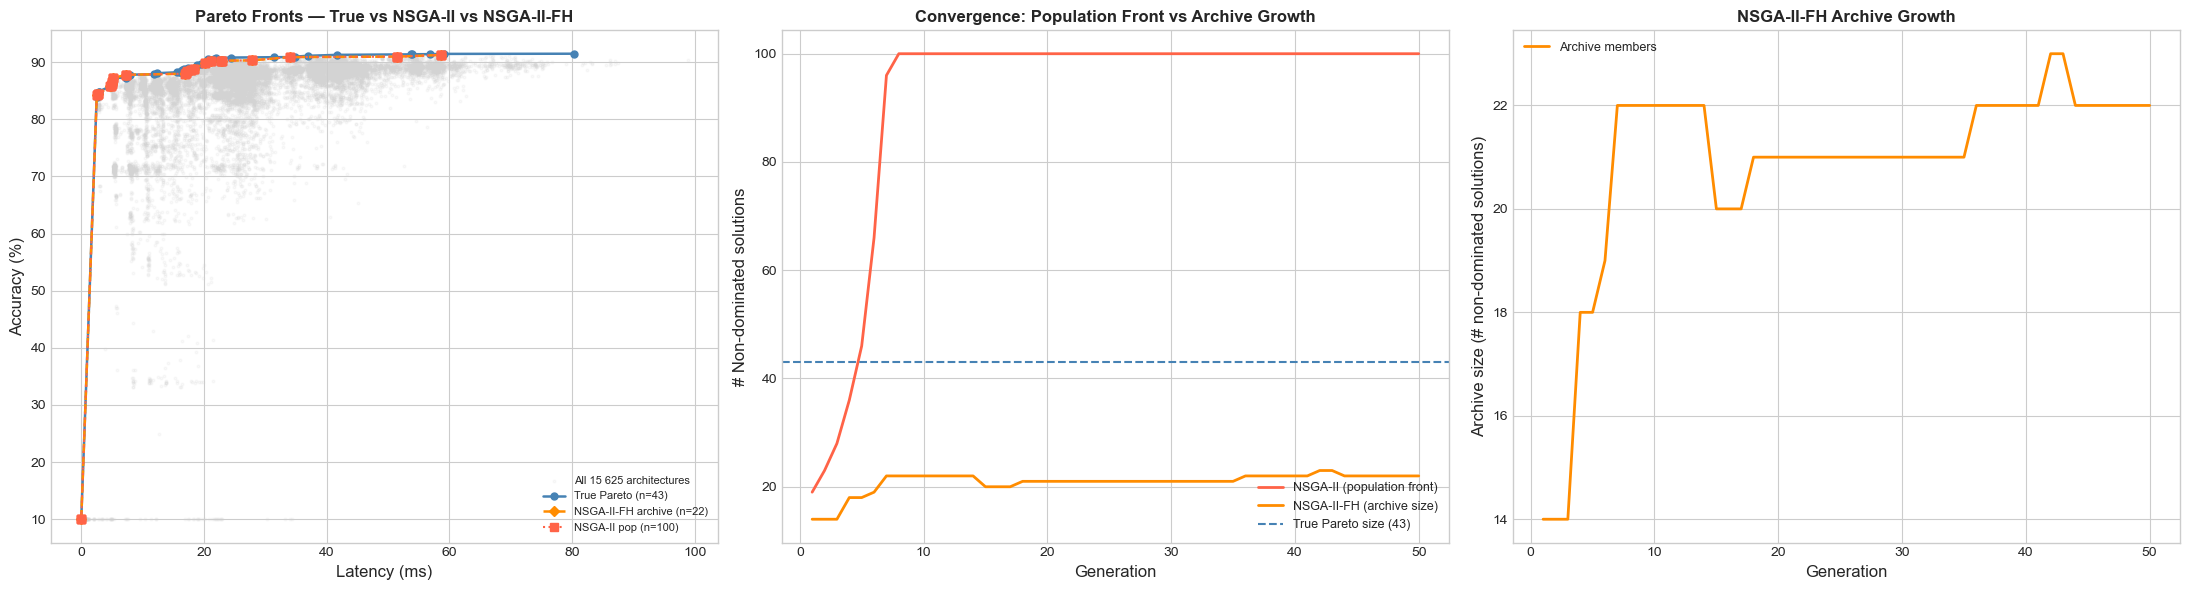

Figure saved → C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/working/nsga2_fh\nsga2_fh_comparison.png


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(22, 6))

# ── Panel A: All three Pareto fronts ─────────────────────────────────────────
ax = axes[0]
ax.scatter(df_all["latency"], df_all["accuracy"],
           s=4, alpha=0.12, color="lightgray", label="All 15 625 architectures")

tp_s = true_pareto.sort_values("latency")
ax.plot(tp_s["latency"], tp_s["accuracy"],
        "o-", color="steelblue", markersize=5, linewidth=1.8,
        label=f"True Pareto (n={len(true_pareto)})")

fh_s = fh_pareto.sort_values("latency")
ax.plot(fh_s["latency"], fh_s["accuracy"],
        "D--", color="darkorange", markersize=5, linewidth=1.8,
        label=f"NSGA-II-FH archive (n={len(fh_pareto)})")

np_s = nsga2_pareto.sort_values("latency")
ax.plot(np_s["latency"], np_s["accuracy"],
        "s:", color="tomato", markersize=6, linewidth=1.5,
        label=f"NSGA-II pop (n={len(nsga2_pareto)})")

ax.set_xlabel("Latency (ms)", fontsize=12)
ax.set_ylabel("Accuracy (%)", fontsize=12)
ax.set_title("Pareto Fronts — True vs NSGA-II vs NSGA-II-FH",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=8)

# ── Panel B: Pareto front size convergence ────────────────────────────────────
ax2 = axes[1]
hist_nsga2_df = pd.DataFrame(hist_nsga2)
hist_fh_df    = pd.DataFrame(hist_fh)

ax2.plot(hist_nsga2_df["generation"], hist_nsga2_df["pareto_front_size"],
         color="tomato", linewidth=2, label="NSGA-II (population front)")
ax2.plot(hist_fh_df["generation"], hist_fh_df["archive_size"],
         color="darkorange", linewidth=2, label="NSGA-II-FH (archive size)")
ax2.axhline(y=len(true_pareto), color="steelblue", linestyle="--",
            label=f"True Pareto size ({len(true_pareto)})")

ax2.set_xlabel("Generation", fontsize=12)
ax2.set_ylabel("# Non-dominated solutions", fontsize=12)
ax2.set_title("Convergence: Population Front vs Archive Growth",
              fontsize=12, fontweight="bold")
ax2.legend(fontsize=9)

# ── Panel C: Archive hypercube occupancy over generations ─────────────────────
ax3 = axes[2]
ax3.plot(hist_fh_df["generation"], hist_fh_df["archive_size"],
         color="darkorange", linewidth=2, label="Archive members")
ax3.set_xlabel("Generation", fontsize=12)
ax3.set_ylabel("Archive size (# non-dominated solutions)", fontsize=12)
ax3.set_title("NSGA-II-FH Archive Growth", fontsize=12, fontweight="bold")
ax3.legend(fontsize=9)

plt.tight_layout()
out_path = os.path.join(OUTPUT_ROOT, "nsga2_fh_comparison.png")
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figure saved → {out_path}")


## 12 · Zoomed Pareto front (low-latency region)

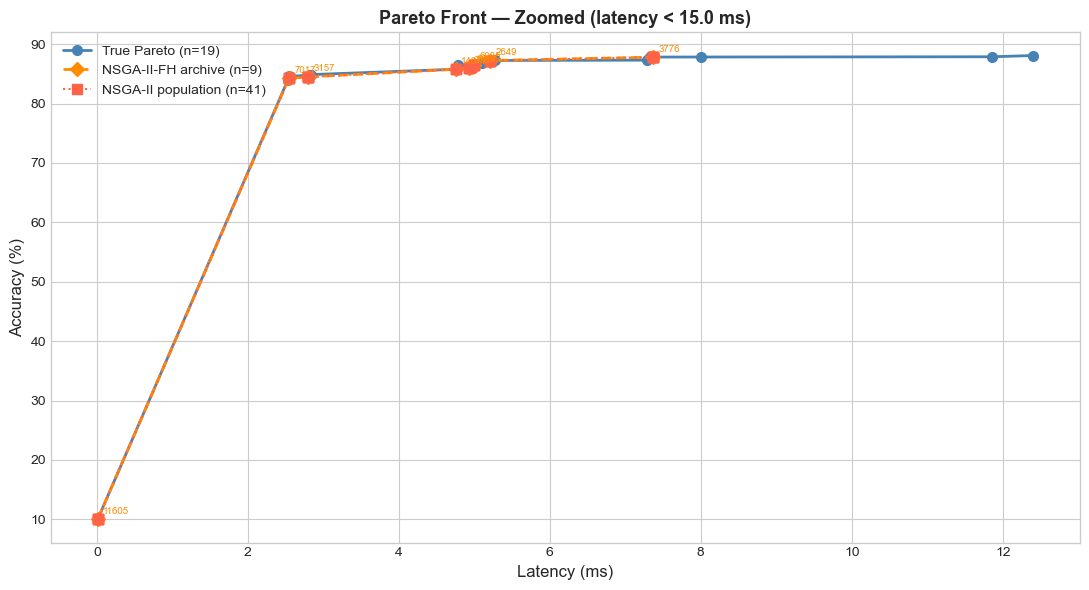

Figure saved → C:\Users\hp\Desktop\ETUDES\S2\Projet\Code\hwnas-with-metaheuristics-project/working/nsga2_fh\nsga2_fh_zoomed.png


In [13]:
fig, ax = plt.subplots(figsize=(11, 6))

LAT_THRESH = 15.0   # ms — practical deployment region

tp_z  = true_pareto[true_pareto["latency"] < LAT_THRESH].sort_values("latency")
np_z  = nsga2_pareto[nsga2_pareto["latency"] < LAT_THRESH].sort_values("latency")
fh_z  = fh_pareto[fh_pareto["latency"] < LAT_THRESH].sort_values("latency")

ax.plot(tp_z["latency"], tp_z["accuracy"],
        "o-", color="steelblue", markersize=7, linewidth=2,
        label=f"True Pareto (n={len(tp_z)})")
ax.plot(fh_z["latency"], fh_z["accuracy"],
        "D--", color="darkorange", markersize=7, linewidth=2,
        label=f"NSGA-II-FH archive (n={len(fh_z)})")
ax.plot(np_z["latency"], np_z["accuracy"],
        "s:", color="tomato", markersize=7, linewidth=1.5,
        label=f"NSGA-II population (n={len(np_z)})")

# Annotate FH archive points
for _, row in fh_z.iterrows():
    ax.annotate(f"{int(row['arch_index'])}",
                (row["latency"], row["accuracy"]),
                textcoords="offset points", xytext=(4, 4),
                fontsize=7, color="darkorange")

ax.set_xlabel("Latency (ms)", fontsize=12)
ax.set_ylabel("Accuracy (%)", fontsize=12)
ax.set_title(f"Pareto Front — Zoomed (latency < {LAT_THRESH} ms)",
             fontsize=13, fontweight="bold")
ax.legend(fontsize=10)
plt.tight_layout()
out_path = os.path.join(OUTPUT_ROOT, "nsga2_fh_zoomed.png")
plt.savefig(out_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Figure saved → {out_path}")


## 13 · Best architecture selection (distance to ideal point)

In [14]:
def best_by_ideal(df: pd.DataFrame, label=""):
    """Find the architecture closest to the ideal point (max acc, min lat)."""
    d = df.copy()
    d["acc_norm"] = (d["accuracy"] - d["accuracy"].min()) / (d["accuracy"].max() - d["accuracy"].min() + 1e-8)
    d["lat_norm"] = (d["latency"]  - d["latency"].min())  / (d["latency"].max()  - d["latency"].min()  + 1e-8)
    d["dist"]     = np.sqrt((d["acc_norm"] - 1.0) ** 2 + (d["lat_norm"] - 0.0) ** 2)
    best = d.loc[d["dist"].idxmin()]
    print(f"\n── Best architecture [{label}] ──")
    print(f"  Arch index : {int(best['arch_index'])}")
    print(f"  Accuracy   : {best['accuracy']:.4f}%")
    print(f"  Latency    : {best['latency']:.4f} ms")
    print(f"  Ideal dist : {best['dist']:.6f}")
    return best

best_nsga2 = best_by_ideal(nsga2_pareto, "NSGA-II population")
best_fh    = best_by_ideal(fh_pareto,    "NSGA-II-FH archive")
best_true  = best_by_ideal(true_pareto,  "True Pareto (exhaustive)")

print("\n── Top 10 NSGA-II-FH archive solutions (closest to ideal) ──")
df_arc = fh_pareto.copy()
df_arc["acc_norm"] = (df_arc["accuracy"] - df_arc["accuracy"].min()) / (df_arc["accuracy"].max() - df_arc["accuracy"].min() + 1e-8)
df_arc["lat_norm"] = (df_arc["latency"]  - df_arc["latency"].min())  / (df_arc["latency"].max()  - df_arc["latency"].min()  + 1e-8)
df_arc["dist"]     = np.sqrt((df_arc["acc_norm"] - 1.0) ** 2 + (df_arc["lat_norm"] - 0.0) ** 2)
display(df_arc.sort_values("dist").head(10)[["arch_index", "accuracy", "latency", "dist"]])



── Best architecture [NSGA-II population] ──
  Arch index : 3157
  Accuracy   : 84.4800%
  Latency    : 2.8023 ms
  Ideal dist : 0.096155

── Best architecture [NSGA-II-FH archive] ──
  Arch index : 3157
  Accuracy   : 84.4800%
  Latency    : 2.8023 ms
  Ideal dist : 0.096155

── Best architecture [True Pareto (exhaustive)] ──
  Arch index : 2649
  Accuracy   : 87.2400%
  Latency    : 5.2035 ms
  Ideal dist : 0.083016

── Top 10 NSGA-II-FH archive solutions (closest to ideal) ──


,arch_index,accuracy,latency,dist
19,3157,84.48,2.802269,0.096155
20,7017,84.23,2.544041,0.096796
14,2649,87.24,5.203499,0.101488
15,6985,86.51,4.995646,0.103229
18,14677,85.77,4.755259,0.105477
16,6087,86.13,4.962073,0.105493
17,7937,85.92,4.933007,0.106671
13,3776,87.80,7.363472,0.132456
12,6986,87.99,16.910786,0.291022
11,7032,88.20,17.091469,0.293731


In [ ]:
# test 
true_indices = set(true_pareto["arch_index"])
archive_indices = set(fh_pareto["arch_index"])
found = true_indices & archive_indices

print(f"True Pareto indices: {sorted(true_indices)[:10]}...")  
print(f"Archive indices: {sorted(archive_indices)}")
print(f"Found in true Pareto: {sorted(found)}")
print(f"Not in true Pareto (locally optimal only): {sorted(archive_indices - found)}")

True Pareto indices: [1459, 1962, 1973, 2035, 2058, 2649, 2952, 4099, 4227, 4432]...
Archive indices: [2136, 2648, 2649, 2904, 3015, 3157, 3192, 3776, 6087, 6985, 6986, 6999, 7017, 7030, 7032, 7937, 8135, 8449, 11605, 12231, 12279, 14677]
Found in true Pareto: [2649, 6999, 7030, 14677]
Not in true Pareto (locally optimal only): [2136, 2648, 2904, 3015, 3157, 3192, 3776, 6087, 6985, 6986, 7017, 7032, 7937, 8135, 8449, 11605, 12231, 12279]
